# GARCH vol-timing on trend

Trend forecast (`strategies.trend`) multiplied by a per-asset GARCH(1,1) vol-timing multiplier

$$m_T = 	ext{clip}\left(\left(rac{\sigma^{	ext{long-run}}_T}{\sigma^{	ext{GARCH}}_{T+1|T}}ight)^{p},\ 	ext{floor},\ 	ext{cap}ight)$$

GARCH is refitted every `refit_every` days on an expanding window. In between, the recursion runs with frozen parameters, so row $T$ only uses data up to $T$. The backtester divides by a rolling 100-day vol afterwards, so the net tilt is roughly `rolling_vol / garch_vol`, which puts the faster reaction of GARCH to vol shocks to use.

All the logic is in [garch_lib.py](garch_lib.py).

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

NOTEBOOK_FILE = globals().get("__vsc_ipynb_file__")
HERE = Path(NOTEBOOK_FILE).resolve().parent if NOTEBOOK_FILE else Path.cwd()
ROOT = HERE if (HERE / "src").exists() else HERE.parent
SOREN = ROOT / "Søren"
for path in (ROOT / "src", SOREN):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import garch_lib
from backtest import Backtest, paired_bootstrap
from backtest.pipeline import load_data
from strategies import trend

prices = load_data(ROOT / "prices" / "example_prices.csv")
assets = [c for c in prices.columns if c != "AsOfDate"]
bt = Backtest(prices)
prices.head()

AsOfDate,diamonds,butter,cars,cucumber,bananas
date,f64,f64,f64,f64,f64
2000-01-03,1578.85,923.03,1231.12,1036.35,669.36
2000-01-04,1576.77,926.42,1231.34,1037.28,668.78
2000-01-05,1575.44,927.01,1229.38,1038.33,666.96
2000-01-06,1574.65,928.27,1230.93,1038.07,674.68
2000-01-07,1575.08,929.76,1232.27,1039.12,677.95


## 1. GARCH sanity checks
Fitted parameters over time (they change only at refits) and persistence α+β.

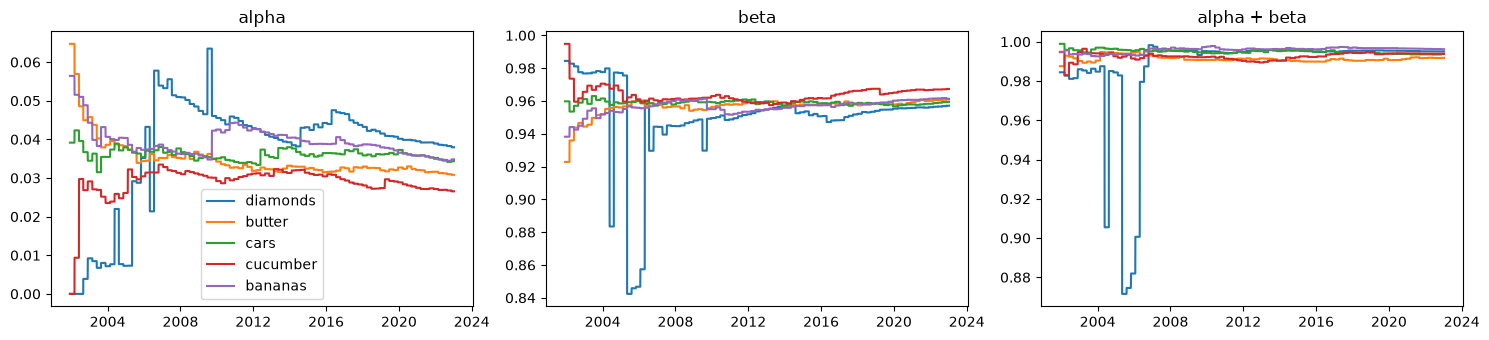

In [2]:
paths = garch_lib.garch_paths(prices)
dates = prices["AsOfDate"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharex=True)
for asset, path in paths.items():
    axes[0].plot(dates, path.alpha, label=asset)
    axes[1].plot(dates, path.beta, label=asset)
    axes[2].plot(dates, path.alpha + path.beta, label=asset)
for ax, title in zip(axes, ["alpha", "beta", "alpha + beta"]):
    ax.set_title(title)
axes[0].legend()
plt.tight_layout()

GARCH forecast vol vs the pipeline's rolling 100-day RMS vol and realised |change|.

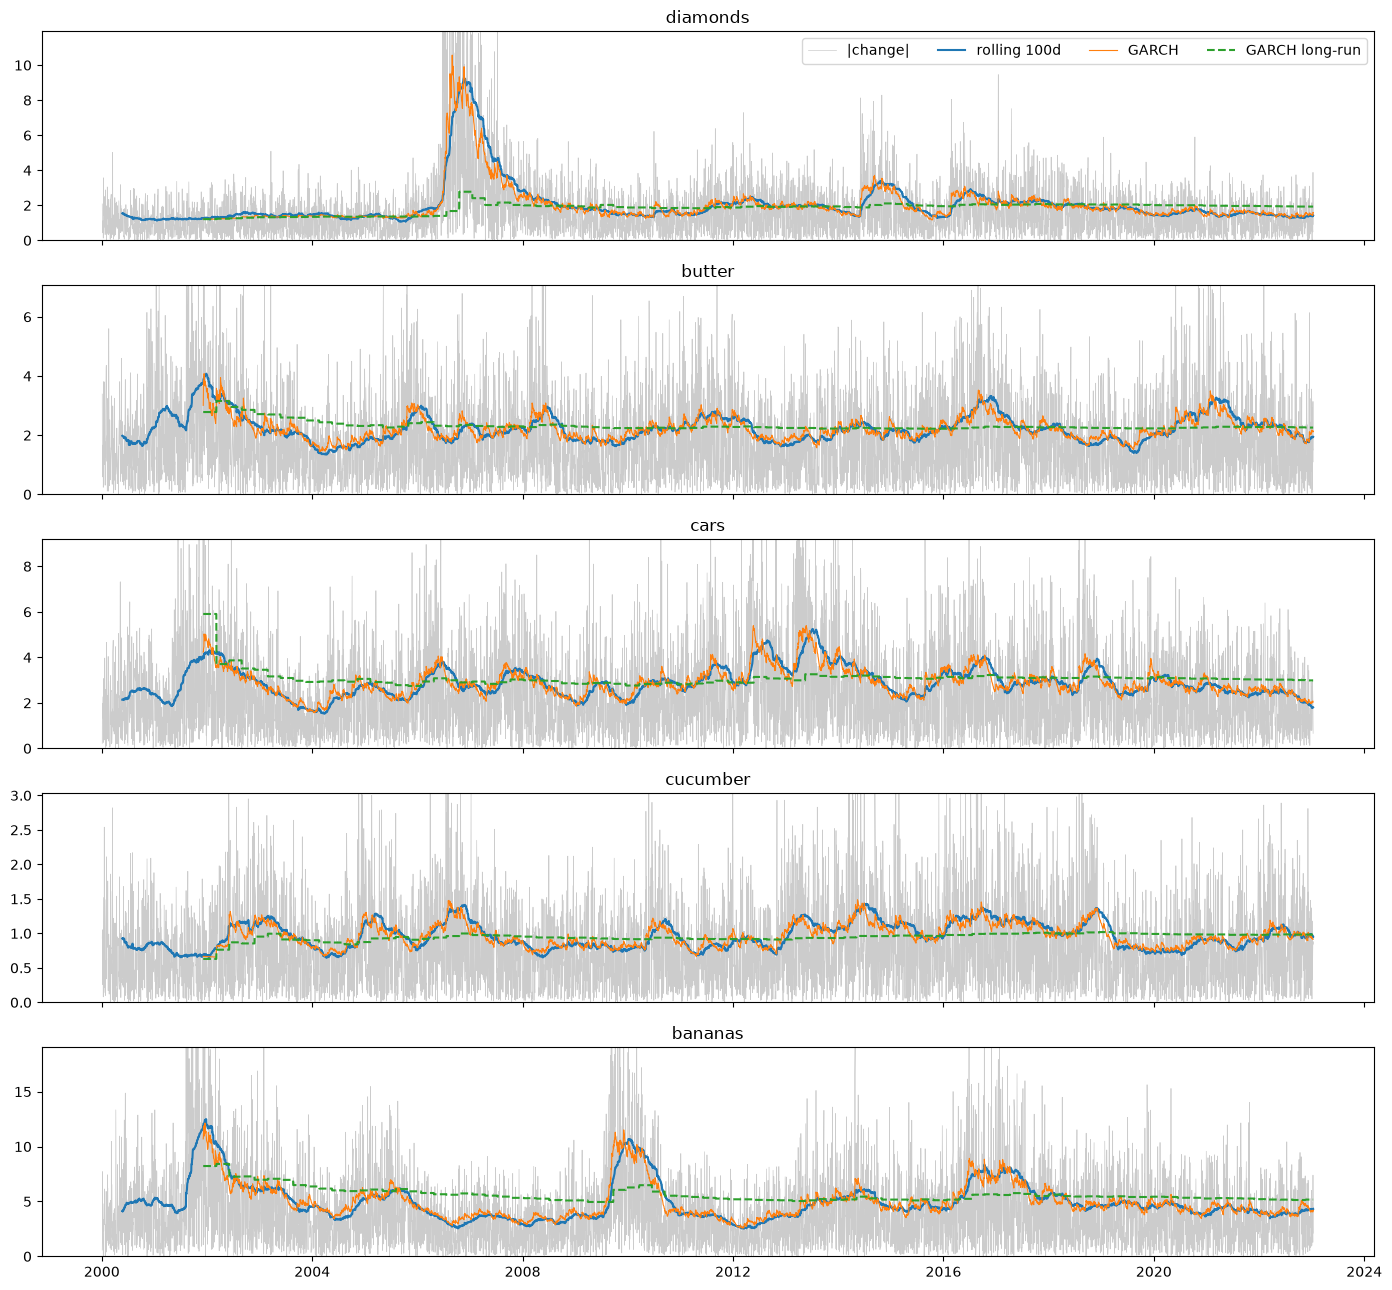

In [3]:
fig, axes = plt.subplots(len(assets), 1, figsize=(14, 2.6 * len(assets)), sharex=True)
for ax, asset in zip(axes, assets):
    changes = prices[asset].diff()
    rolling = (changes**2).rolling_mean(100).sqrt().to_numpy()
    ax.plot(dates, changes.abs().to_numpy(), color="0.8", lw=0.5, label="|change|")
    ax.plot(dates, rolling, label="rolling 100d")
    ax.plot(dates, paths[asset].sigma, label="GARCH", lw=0.8)
    ax.plot(dates, paths[asset].longrun, ls="--", label="GARCH long-run")
    ax.set_title(asset)
    ax.set_ylim(0, np.nanpercentile(changes.abs().to_numpy(), 99.5))
axes[0].legend(ncol=4)
plt.tight_layout()

### Forecast accuracy
Out-of-sample loss of each variance forecast (made at $T$) against the realised $r^2_{T+1}$. QLIKE $= rac{r^2}{h} - \lograc{r^2}{h} - 1$ is robust to noisy proxies; lower is better. The scores only use days where all three forecasts exist.

In [4]:
def losses(asset):
    r = prices[asset].diff().to_numpy()
    target = np.roll(r, -1) ** 2  # r^2 of T+1, aligned to row T
    s = pl.Series(r, nan_to_null=True)
    forecasts = {
        "garch": paths[asset].sigma ** 2,
        "rolling100": (s**2).rolling_mean(100).to_numpy(),
        "ewma94": (s**2).ewm_mean(alpha=0.06, adjust=False).to_numpy(),
    }
    ok = np.isfinite(target) & (target > 0) & np.all([np.isfinite(h) for h in forecasts.values()], axis=0)
    ok[-1] = False
    row = {"asset": asset}
    for name, h in forecasts.items():
        ratio = target[ok] / h[ok]
        row[f"qlike_{name}"] = float(np.mean(ratio - np.log(ratio) - 1))
    return row

pl.DataFrame([losses(a) for a in assets])

asset,qlike_garch,qlike_rolling100,qlike_ewma94
str,f64,f64,f64
"""diamonds""",1.270171,1.286148,1.266046
"""butter""",1.294203,1.300682,1.306563
"""cars""",1.259264,1.276803,1.2682
"""cucumber""",1.288428,1.293496,1.296751
"""bananas""",1.291555,1.304111,1.299896


## 2. Multiplier
Distribution and time series of the vol-timing multiplier (default parameters).

statistic,diamonds,butter,cars,cucumber,bananas
str,f64,f64,f64,f64,f64
"""count""",5956.0,5956.0,5956.0,5956.0,5956.0
"""null_count""",0.0,0.0,0.0,0.0,0.0
"""mean""",1.023717,1.067186,1.084612,0.998657,1.193372
"""std""",0.215385,0.163922,0.198055,0.147529,0.263712
"""min""",0.5,0.640713,0.535187,0.647382,0.510491
"""25%""",0.9369,0.968092,0.971144,0.885528,1.0
"""50%""",1.0,1.049132,1.061131,1.0,1.175503
"""75%""",1.166057,1.173397,1.199976,1.104344,1.362555
"""max""",1.719527,1.683768,1.869682,1.381915,2.0


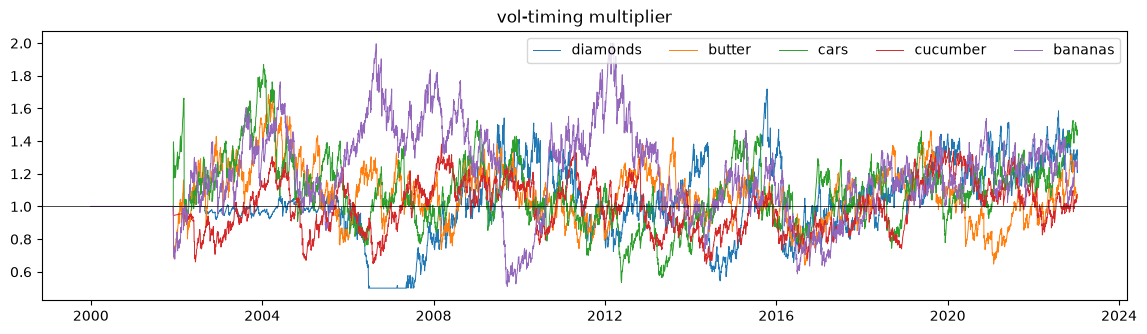

In [5]:
timing = garch_lib.vol_timing(prices)
fig, ax = plt.subplots(figsize=(14, 3.5))
for asset in assets:
    ax.plot(dates, timing[asset].to_numpy(), lw=0.7, label=asset)
ax.axhline(1, color="k", lw=0.5)
ax.legend(ncol=5)
ax.set_title("vol-timing multiplier")
timing.drop("AsOfDate").describe()

## 3. Baseline vs GARCH vol-timing (dev period, leakage check on)

In [6]:
baseline = bt.run(trend.forecast, name="trend")
garch = bt.run(garch_lib.forecast, name="garch_trend")
timing_only = bt.run(garch_lib.timing_only, name="timing_only")
pl.DataFrame([baseline.figures, garch.figures, timing_only.figures]).insert_column(
    0, pl.Series("strategy", ["trend", "garch_trend", "timing_only"])
)

strategy,adjusted_sharpe,sharpe,sharpe_ex_slippage,sharpe_1d_lag,skewness,kurtosis,av_holding,position_bias
str,f64,f64,f64,f64,f64,f64,f64,f64
"""trend""",0.717021,0.720384,0.720595,0.700749,0.064462,3.573804,32.842919,0.003388
"""garch_trend""",0.698211,0.703885,0.704136,0.71465,0.053982,3.697292,27.866549,0.003667
"""timing_only""",0.159731,0.15989,0.159968,0.166988,-0.027963,3.23867,87.037443,1.0


In [7]:
comparison = bt.compare({"trend": trend.forecast, "garch_trend": garch_lib.forecast}, check_leakage=False)
print(comparison)
paired_bootstrap(garch.returns, baseline.returns)

┌──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
│ strategy ┆ adjusted ┆ sharpe   ┆ sharpe_e ┆ sharpe_1 ┆ skewness ┆ kurtosis ┆ av_holdi ┆ position │
│ ---      ┆ _sharpe  ┆ ---      ┆ x_slippa ┆ d_lag    ┆ ---      ┆ ---      ┆ ng       ┆ _bias    │
│ str      ┆ ---      ┆ f64      ┆ ge       ┆ ---      ┆ f64      ┆ f64      ┆ ---      ┆ ---      │
│          ┆ f64      ┆          ┆ ---      ┆ f64      ┆          ┆          ┆ f64      ┆ f64      │
│          ┆          ┆          ┆ f64      ┆          ┆          ┆          ┆          ┆          │
╞══════════╪══════════╪══════════╪══════════╪══════════╪══════════╪══════════╪══════════╪══════════╡
│ trend    ┆ 0.717021 ┆ 0.720384 ┆ 0.720595 ┆ 0.700749 ┆ 0.064462 ┆ 3.573804 ┆ 32.84291 ┆ 0.003388 │
│          ┆          ┆          ┆          ┆          ┆          ┆          ┆ 9        ┆          │
│ garch_tr ┆ 0.698211 ┆ 0.703885 ┆ 0.704136 ┆ 0.71465  ┆ 0.053982 ┆ 3.697292 ┆ 27.86654 ┆ 0

Bootstrap(estimate=-0.018810589866981697, low=-0.10665674172175066, high=0.06865391307356859, p_at_most_zero=0.6663, block=10.0, draws=array([-0.00761533,  0.0576983 ,  0.05914867, ...,  0.01757227,
       -0.0428219 , -0.1182867 ], shape=(10000,)))

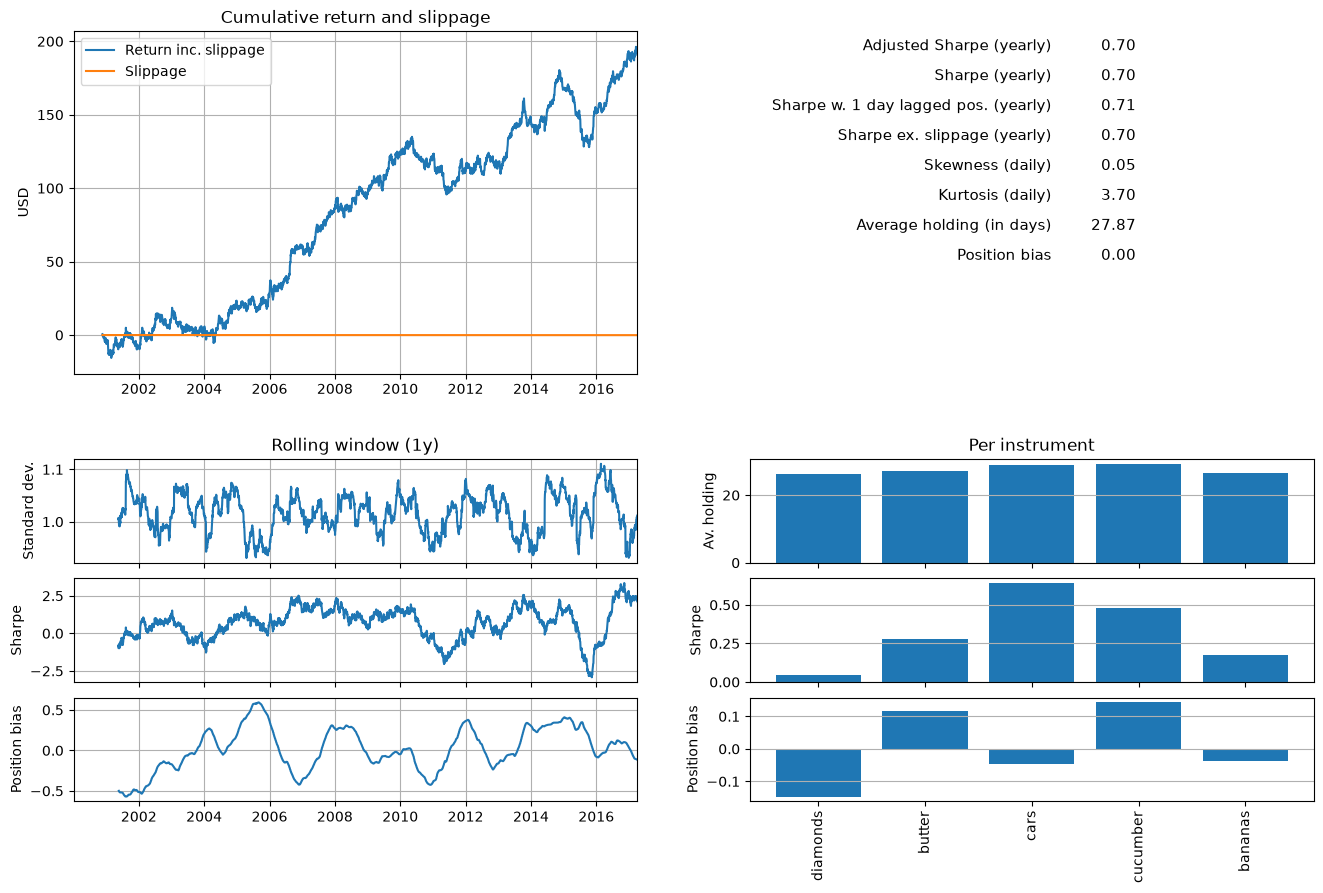

In [8]:
garch.plot()

## 4. Parameter sweep (dev only, leakage check off)
`power`, `floor` and `cap` reuse the cached GARCH fits, so they're cheap. `refit_every` and `dist` need new fits (about a minute each).

In [9]:
sweep = bt.sweep(
    garch_lib.forecast,
    check_leakage=False,
    power=[0.5, 1.0, 1.5, 2.0],
    floor=[0.25, 0.5],
    cap=[1.5, 2.0, 3.0],
)
sweep.sort("adjusted_sharpe", descending=True).head(10)

power,floor,cap,adjusted_sharpe,sharpe,sharpe_ex_slippage,sharpe_1d_lag,skewness,kurtosis,av_holding,position_bias
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0.5,0.5,1.5,0.714653,0.719014,0.719244,0.71509,0.052906,3.575867,30.417554,0.003121
0.5,0.5,2.0,0.714653,0.719014,0.719244,0.71509,0.052906,3.575867,30.417554,0.003121
0.5,0.5,3.0,0.714653,0.719014,0.719244,0.71509,0.052906,3.575867,30.417554,0.003121
0.5,0.25,1.5,0.714102,0.718482,0.718712,0.714715,0.052016,3.573038,30.414649,0.002943
0.5,0.25,2.0,0.714102,0.718482,0.718712,0.714715,0.052016,3.573038,30.414649,0.002943
0.5,0.25,3.0,0.714102,0.718482,0.718712,0.714715,0.052016,3.573038,30.414649,0.002943
1.0,0.5,1.5,0.699424,0.705024,0.705273,0.717107,0.051154,3.673761,28.087905,0.003561
1.0,0.25,1.5,0.699069,0.704875,0.705124,0.718079,0.040914,3.630065,28.083736,0.002806
1.0,0.25,3.0,0.698301,0.70415,0.704401,0.715973,0.043553,3.64949,27.862144,0.002828


In [10]:
sweep_fit = bt.sweep(
    garch_lib.forecast,
    check_leakage=False,
    refit_every=[21, 63, 126],
    dist=["normal", "t"],
)
sweep_fit.sort("adjusted_sharpe", descending=True)

refit_every,dist,adjusted_sharpe,sharpe,sharpe_ex_slippage,sharpe_1d_lag,skewness,kurtosis,av_holding,position_bias
i64,str,f64,f64,f64,f64,f64,f64,f64,f64
126,"""normal""",0.701381,0.707173,0.707425,0.717939,0.051744,3.685735,27.735491,0.005953
63,"""t""",0.698211,0.703885,0.704136,0.71465,0.053982,3.697292,27.866549,0.003667
63,"""normal""",0.696154,0.701893,0.702145,0.710419,0.051615,3.692478,27.738319,0.00399
21,"""t""",0.69463,0.700084,0.700335,0.710127,0.055679,3.699623,27.877996,0.003068
21,"""normal""",0.691988,0.697441,0.697693,0.704292,0.053989,3.695411,27.727963,0.00339
126,"""t""",0.686584,0.691823,0.692074,0.700985,0.052539,3.683457,27.845368,0.003327


In [11]:
sweep_ref = bt.sweep(garch_lib.forecast, check_leakage=False, ref=["longrun", "expanding"], power=[0.5, 1.0])
sweep_ref.sort("adjusted_sharpe", descending=True)

ref,power,adjusted_sharpe,sharpe,sharpe_ex_slippage,sharpe_1d_lag,skewness,kurtosis,av_holding,position_bias
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""longrun""",0.5,0.714653,0.719014,0.719244,0.71509,0.052906,3.575867,30.417554,0.003121
"""expanding""",0.5,0.707204,0.711444,0.711674,0.707387,0.05224,3.576306,30.398358,0.003161
"""longrun""",1.0,0.698211,0.703885,0.704136,0.71465,0.053982,3.697292,27.866549,0.003667
"""expanding""",1.0,0.683332,0.688609,0.68886,0.698555,0.053408,3.698102,27.888659,0.003696


## 5. Diagnostics: per year, per asset, and the cost model

In [12]:
pl.concat(
    [baseline.by_year().select("year", pl.col("sharpe").alias("trend")),
     garch.by_year().select(pl.col("sharpe").alias("garch_trend"))],
    how="horizontal",
)

year,trend,garch_trend
i32,f64,f64
2000,-2.832579,-2.832579
2001,-0.200836,-0.195626
2002,1.195136,1.144717
2003,-0.481184,-0.375176
2004,1.249668,0.942049
…,…,…
2013,1.763199,1.903624
2014,1.519448,1.243326
2015,-0.869131,-0.979304


In [13]:
garch.by_instrument()

instrument,sharpe_ex_slippage,av_holding,position_bias
str,f64,f64,f64
"""diamonds""",0.044375,26.20986,-0.146688
"""butter""",0.279591,27.047866,0.117002
"""cars""",0.640176,28.855018,-0.045858
"""cucumber""",0.480596,29.204715,0.143399
"""bananas""",0.172153,26.550504,-0.038711


In [14]:
bt_lynx = Backtest(prices, scoring="lynx")
pl.DataFrame([
    bt_lynx.run(trend.forecast, check_leakage=False).figures,
    bt_lynx.run(garch_lib.forecast, check_leakage=False).figures,
]).insert_column(0, pl.Series("strategy", ["trend", "garch_trend"]))

strategy,adjusted_sharpe,sharpe,sharpe_ex_slippage,sharpe_1d_lag,skewness,kurtosis,av_holding,position_bias
str,f64,f64,f64,f64,f64,f64,f64,f64
"""trend""",0.689416,0.69219,0.730105,0.672502,0.064801,3.57519,32.481415,0.003388
"""garch_trend""",0.663723,0.668378,0.713389,0.679626,0.054189,3.698457,27.27435,0.003667


## 6. Holdout (run once, with the parameters chosen on dev)
Fill in `CHOSEN` from the sweeps above, then run this cell **once**.

In [15]:
from functools import partial

CHOSEN = dict(power=1.0, floor=0.5, cap=2.0)  # <- set from the dev sweeps
RUN_HOLDOUT = False

if RUN_HOLDOUT:
    final = bt.run(partial(garch_lib.forecast, **CHOSEN), period="holdout", name="garch_trend")
    base_hold = bt.run(trend.forecast, period="holdout", name="trend")
    print(final.figures)
    print(base_hold.figures)